In [ ]:
import sys

sys.path.append("../src")
from pipeline import historical_data_preparation_pipeline
from functions import historical_feature_generation
import pandas as pd
import numpy as np
from scipy.special import expit
from sklearn.model_selection import train_test_split

df = pd.read_csv("../data/whoop_fitness_dataset_100k.csv")


functions.py imported successfully
pipeline.py imported successfully


In [2]:
from sklearn.model_selection import GroupShuffleSplit

# Keep recovery_score temporarily for historical feature generation
data = df.copy()

gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# splits the whole data by user id (80/20), get their indexes
train_idx, test_idx = next(
    gss.split(
        data,
        data["recovery_score"],
        groups=data["user_id"]
    )
)

# grab the users' data based on indexes
train_data = data.iloc[train_idx].copy()
test_data = data.iloc[test_idx].copy()

gss_valid = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

# splits train data by user id (80/20), get their indexes 
train_idx, valid_idx = next(
    gss_valid.split(
        train_data,
        train_data["recovery_score"],
        groups=train_data["user_id"]
    )
)

# grab the users' data based on indexes
train_data_final = train_data.iloc[train_idx].copy()
valid_data = train_data.iloc[valid_idx].copy()

# Keep recovery_score temporarily in X, it will be later drop in the pipeline
x_train = train_data_final.copy()
x_test = test_data.copy()
x_valid = valid_data.copy()

# Separate target AFTER splitting
y_train = train_data_final["recovery_score"]
y_valid = valid_data["recovery_score"]
y_test = test_data["recovery_score"]


y_test.to_csv("../data/y_test.csv", index=False)

In [3]:
x_train_processed = historical_data_preparation_pipeline.fit_transform(
    x_train,
    y_train,
    feature_selection__groups=x_train["user_id"] # tell the feature selection transformer to group using user id
)

x_valid_processed = historical_data_preparation_pipeline.transform(
    x_valid
)

x_test_processed = historical_data_preparation_pipeline.transform(
    x_test
)

In [6]:
# print out the selected/survived features
rfecv = historical_data_preparation_pipeline.named_steps["feature_selection"] 

feature_names = rfecv.feature_names_in_

selected_features = feature_names[rfecv.support_]

print("Number of selected features:", len(selected_features))
print(selected_features)

Number of selected features: 64
['gender_Female' 'activity_type_CrossFit' 'activity_type_Cycling'
 'activity_type_HIIT' 'activity_type_Running'
 'activity_type_Weight Training' 'fitness_level' 'age' 'weight_kg'
 'height_cm' 'day_strain' 'sleep_hours' 'sleep_efficiency'
 'light_sleep_hours' 'deep_sleep_hours' 'hrv' 'resting_heart_rate'
 'hrv_baseline' 'rhr_baseline' 'respiratory_rate' 'skin_temp_deviation'
 'calories_burned' 'activity_duration_min' 'activity_strain'
 'avg_heart_rate' 'activity_calories' 'hr_zone_1_min' 'hr_zone_2_min'
 'hr_zone_5_min' 'low_intensity_min' 'hrv_ratio' 'rhr_ratio'
 'rem_sleep_hours_ratio' 'deep_sleep_hours_ratio' 'bmi' 'month'
 'month_sin' 'day_of_week_num' 'hrv_rhr_ratio' 'hrv_deviation'
 'rhr_deviation' 'strain_sleep_ratio' 'day_strain_rolling_mean_7d'
 'sleep_hours_rolling_mean_7d' 'hrv_rolling_mean_7d'
 'previous_recovery_score' 'previous_sleep_hours'
 'previous_sleep_efficiency' 'previous_hrv' 'previous_resting_heart_rate'
 'day_strain_change' 'sleep_

In [7]:
# print out the removed features
removed_features = feature_names[~rfecv.support_]

print("Removed features:")
print(removed_features)

Removed features:
['gender_Male' 'activity_type_Rest Day' 'activity_type_Swimming'
 'activity_type_Walking' 'activity_type_Yoga' 'sleep_performance'
 'rem_sleep_hours' 'wake_ups' 'time_to_fall_asleep_min'
 'workout_completed' 'max_heart_rate' 'hr_zone_3_min' 'hr_zone_4_min'
 'high_intensity_min' 'month_cos' 'day_of_week_sin' 'day_of_week_cos'
 'is_weekend' 'sleep_quality_score' 'previous_day_strain'
 'previous_calories_burned' 'sleep_hours_vs_personal_mean'
 'hrv_sleep_interaction' 'is_first_record']


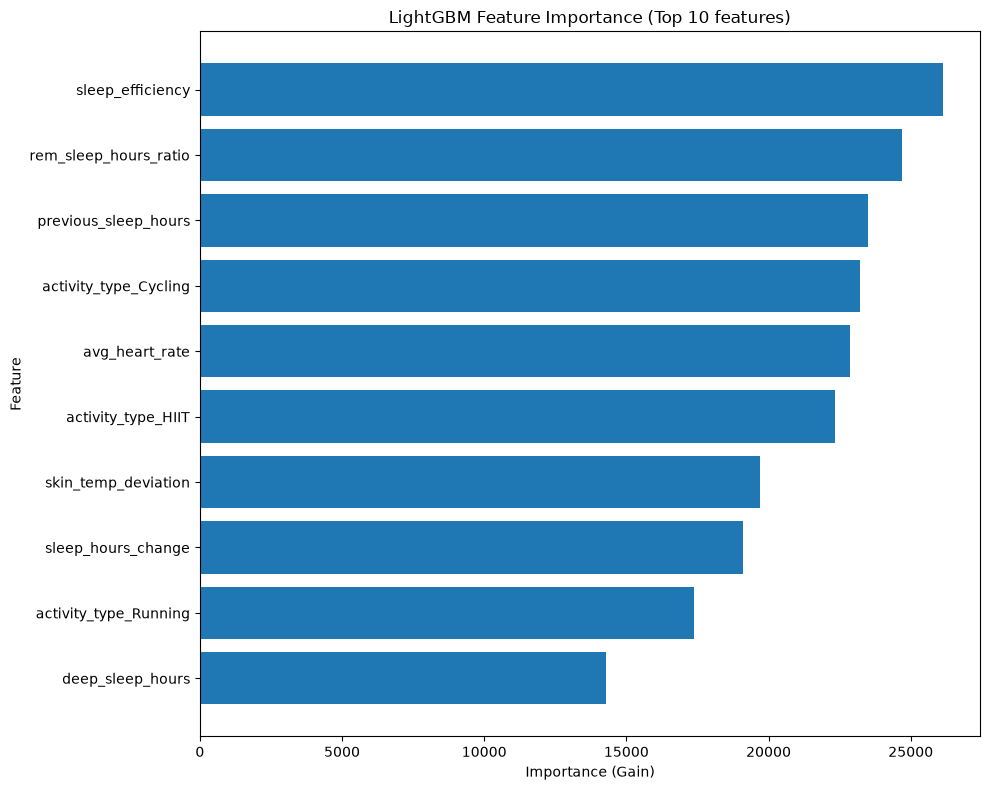

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

rfecv = historical_data_preparation_pipeline.named_steps["feature_selection"]

# Estimator used by RFECV (LGBMREgressor)
estimator = rfecv.estimator_

feature_names = rfecv.feature_names_in_
selected_features = feature_names[rfecv.support_]

importance = estimator.feature_importances_

importance_df = pd.DataFrame({
    "feature": selected_features,
    "importance": importance
})

importance_df = importance_df.sort_values(
    "importance",
    ascending=True
).head(10)

plt.figure(figsize=(10, 8))

plt.barh(
    importance_df["feature"],
    importance_df["importance"]
)

plt.xlabel("Importance (Gain)")
plt.ylabel("Feature")
plt.title("LightGBM Feature Importance (Top 10 features)")
plt.tight_layout()

plt.show()

In [9]:
from sklearn.tree import DecisionTreeRegressor

# Decision Tree Regressor
dtr = DecisionTreeRegressor( random_state=42 )

dtr.fit(x_train_processed, y_train)

predict_dtr = dtr.predict(x_test_processed)
predict_dtr = np.clip(predict_dtr, 0, 100)
pd.DataFrame(predict_dtr, columns=["prediction"]).to_csv("../data/predict_dtr.csv", index=False)

from sklearn.ensemble import HistGradientBoostingRegressor

# HistGradient Boosting Regressor
hgbr = HistGradientBoostingRegressor( random_state=42 )

hgbr.fit(x_train_processed, y_train)

predict_hgbr = hgbr.predict(x_test_processed)
predict_hgbr = np.clip(predict_hgbr, 0, 100)
pd.DataFrame(predict_hgbr, columns=["prediction"]).to_csv("../data/predict_hgbr.csv", index=False)

# XGBoost Regressor
from xgboost import XGBRegressor

xgbr = XGBRegressor( random_state=42 )

xgbr.fit(x_train_processed, y_train)

predict_xgbr = xgbr.predict(x_test_processed)
predict_xgbr = np.clip(predict_xgbr, 0, 100)
pd.DataFrame(predict_xgbr, columns=["prediction"]).to_csv("../data/predict_xgbr.csv", index=False)

# LGBM Regressor
from lightgbm import LGBMRegressor

lgbm = LGBMRegressor( random_state=42 )

lgbm.fit(x_train_processed, y_train)

predict_lgbm = lgbm.predict(x_test_processed)
predict_lgbm  = np.clip(predict_lgbm , 0, 100)
pd.DataFrame(predict_lgbm, columns=["prediction"]).to_csv("../data/predict_lgbm.csv", index=False)

In [10]:
import optuna
from sklearn.metrics import root_mean_squared_error
def objective(trial):
    
    params = {
        "n_estimators": trial.suggest_int(
            "n_estimators", 100, 300
        ),
        "num_leaves": trial.suggest_int(
            "num_leaves", 15, 60
        ),
        "learning_rate": trial.suggest_float(
            "learning_rate", 0.01, 0.21
        ),
        "subsample": trial.suggest_float(
            "subsample", 0.7, 1.0
        ),
        "colsample_bytree": trial.suggest_float(
            "colsample_bytree", 0.6, 1.0
        )
    }
    
    model = LGBMRegressor(**params, random_state=42)
    model.fit(x_train_processed, y_train)
    
    predict = model.predict(x_valid_processed)
    
    rmse = root_mean_squared_error(
        y_valid,
        predict,
    )
    
    return rmse
    

c:\Users\Clark Bruce\TE1 machine learning\midterm_project\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [ ]:
import json

sampler = optuna.samplers.TPESampler(seed=42)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study.optimize(
    objective,
    n_trials=100
)

bayesian_params = study.best_params

with open("../results/hyperparameter_tuning/bayesian_hyperparameters.json", "w") as f:
    json.dump(bayesian_params, f, indent=4)
    
print(f"Best trial: trial #{study.best_trial.number} with RMSE of {study.best_value}")
print("Parameters")
print(bayesian_params)

[I 2026-10-14 03:59:52,734] A new study created in memory with name: no-name-06753425-d85e-46ed-8083-644cb8e79a2e
[I 2026-10-14 03:59:53,687] Trial 0 finished with value: 13.292443716616832 and parameters: {'n_estimators': 175, 'num_leaves': 58, 'learning_rate': 0.15639878836228102, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.6624074561769746}. Best is trial 0 with value: 13.292443716616832.
[I 2026-10-14 03:59:54,181] Trial 1 finished with value: 13.196201111316036 and parameters: {'n_estimators': 131, 'num_leaves': 17, 'learning_rate': 0.18323522915498702, 'subsample': 0.8803345035229626, 'colsample_bytree': 0.8832290311184181}. Best is trial 1 with value: 13.196201111316036.
[I 2026-10-14 03:59:54,727] Trial 2 finished with value: 13.32157226016236 and parameters: {'n_estimators': 104, 'num_leaves': 59, 'learning_rate': 0.17648852816008434, 'subsample': 0.7637017332034828, 'colsample_bytree': 0.6727299868828402}. Best is trial 1 with value: 13.196201111316036.
[I 2026-10-

Best trial: trial #47 with RMSE of 13.172561090076881
Parameters
{'n_estimators': 154, 'num_leaves': 16, 'learning_rate': 0.16744522266503778, 'subsample': 0.9104252252979045, 'colsample_bytree': 0.9743104924787827}


In [ ]:
pruner = optuna.pruners.SuccessiveHalvingPruner(
    min_resource=10,
    reduction_factor=3
)

study = optuna.create_study(
    direction="minimize",
    pruner=pruner
)

study.optimize(
    objective,
    n_trials=100
)

successive_halving_params = study.best_params

with open("../results/hyperparameter_tuning/successive_halving_hyperparameters.json", "w") as f:
    json.dump(successive_halving_params, f, indent=4)
    
print(f"Best trial: trial #{study.best_trial.number} with RMSE of {study.best_value}")
print("Parameters")
print(successive_halving_params)

[I 2026-10-14 04:01:43,541] A new study created in memory with name: no-name-27b43a23-59b5-4970-a9ea-8c56ab550e9f
[I 2026-10-14 04:01:44,589] Trial 0 finished with value: 13.124265168798898 and parameters: {'n_estimators': 210, 'num_leaves': 51, 'learning_rate': 0.06270513826711091, 'subsample': 0.756933476549382, 'colsample_bytree': 0.6745503010637297}. Best is trial 0 with value: 13.124265168798898.
[I 2026-10-14 04:01:45,537] Trial 1 finished with value: 13.246752076964253 and parameters: {'n_estimators': 224, 'num_leaves': 38, 'learning_rate': 0.11606319860329414, 'subsample': 0.8173084210919818, 'colsample_bytree': 0.8675254163457193}. Best is trial 0 with value: 13.124265168798898.
[I 2026-10-14 04:01:46,325] Trial 2 finished with value: 13.196693780213945 and parameters: {'n_estimators': 181, 'num_leaves': 33, 'learning_rate': 0.06983599478349341, 'subsample': 0.8403691436519546, 'colsample_bytree': 0.8737678710312458}. Best is trial 0 with value: 13.124265168798898.
[I 2026-10-

Best trial: trial #50 with RMSE of 13.052395953393688
Parameters
{'n_estimators': 214, 'num_leaves': 57, 'learning_rate': 0.04304124131753428, 'subsample': 0.8617185339001809, 'colsample_bytree': 0.6740378865133045}


In [ ]:
sampler = optuna.samplers.CmaEsSampler(seed=42)

study = optuna.create_study(
    direction="minimize",
    sampler=sampler
)

study.optimize(
    objective,
    n_trials=100
)

cmaes_params = study.best_params

with open("../results/hyperparameter_tuning/CMA-ES_hyperparameters.json", "w") as f:
    json.dump(cmaes_params, f, indent=4)
    
print(f"Best trial: trial #{study.best_trial.number} with RMSE of {study.best_value}")
print("Parameters")
print(cmaes_params)

[I 2026-10-14 04:03:58,909] A new study created in memory with name: no-name-534b9e9a-5152-446a-a92d-26a042d514f2
[I 2026-10-14 04:03:59,760] Trial 0 finished with value: 13.292443716616832 and parameters: {'n_estimators': 175, 'num_leaves': 58, 'learning_rate': 0.15639878836228102, 'subsample': 0.8795975452591109, 'colsample_bytree': 0.6624074561769746}. Best is trial 0 with value: 13.292443716616832.
[I 2026-10-14 04:04:00,499] Trial 1 finished with value: 13.180786519376552 and parameters: {'n_estimators': 152, 'num_leaves': 32, 'learning_rate': 0.08327195638461442, 'subsample': 0.8557272612680897, 'colsample_bytree': 0.7874843656877059}. Best is trial 1 with value: 13.180786519376552.
[I 2026-10-14 04:04:01,293] Trial 2 finished with value: 13.127353082766277 and parameters: {'n_estimators': 155, 'num_leaves': 46, 'learning_rate': 0.07851889492255112, 'subsample': 0.8639430399541204, 'colsample_bytree': 0.795808779809538}. Best is trial 2 with value: 13.127353082766277.
[I 2026-10-

Best trial: trial #99 with RMSE of 13.058479272826096
Parameters
{'n_estimators': 130, 'num_leaves': 54, 'learning_rate': 0.06482483082060321, 'subsample': 0.8555479340974093, 'colsample_bytree': 0.7342917080415576}


In [12]:
# LGBM Regressor with hyperparameters from bayesian optimization
from lightgbm import LGBMRegressor

lgbm_bayesian = LGBMRegressor( **bayesian_params, random_state=42 )

lgbm_bayesian.fit(x_train_processed, y_train)

predict_lgbm_bayesian = lgbm_bayesian.predict(x_test_processed)
predict_lgbm_bayesian  = np.clip(predict_lgbm_bayesian , 0, 100)
pd.DataFrame(predict_lgbm_bayesian, columns=["prediction"]).to_csv("../data/predict_lgbm_bayesian.csv", index=False)

In [13]:
# LGBM Regressor with hyperparameters from successive halving optimization
from lightgbm import LGBMRegressor

lgbm_successive_halving = LGBMRegressor( **successive_halving_params, random_state=42 )

lgbm_successive_halving.fit(x_train_processed, y_train)

predict_lgbm_successive_halving = lgbm_successive_halving.predict(x_test_processed)
predict_lgbm_successive_halving  = np.clip(predict_lgbm_successive_halving , 0, 100)
pd.DataFrame(predict_lgbm_successive_halving, columns=["prediction"]).to_csv("../data/predict_lgbm_successive_halving.csv", index=False)

In [14]:
# LGBM Regressor with hyperparameters from CMA-ES optimization
from lightgbm import LGBMRegressor

lgbm_cmaes = LGBMRegressor( **cmaes_params, random_state=42 )

lgbm_cmaes.fit(x_train_processed, y_train)

predict_lgbm_cmaes = lgbm_cmaes.predict(x_test_processed)
predict_lgbm_cmaes  = np.clip(predict_lgbm_cmaes , 0, 100)
pd.DataFrame(predict_lgbm_cmaes, columns=["prediction"]).to_csv("../data/predict_lgbm_cmaes.csv", index=False)